# 6. Receding-horizon updates with one Solver workspace

**Goal:** repeatedly solve the tracking OCP, apply the first acceleration, measure
the new state, and update the problem. This notebook is independent of Tutorial 2;
all model arrays are defined here again.

Each solve minimizes the same quadratic tracking objective subject to double-integrator
dynamics, $|a_k|\le1.2$, $|v_k|\le1$, and terminal target $x_N=(2,0)$.
Only the measured initial state changes between solves.

**Workspace reuse is not warm start.** ICORE still initializes each IPM solve from its
cold-start policy; we reuse allocations and valid prepared model data.


Run the cells from top to bottom. The first `Solver(...)` may compile the native
library. That is setup, not solve time. Installation instructions: [README](../README.md).

All model arrays are constructed below: there is no hidden model builder.
`explain_solution` only checks and reports the already-computed solution.

> **Development transparency:** Substantial portions of ICORE's implementation and documentation were generated and revised with GPT under human direction. Not all details have undergone independent human review. See the [development and review statement](../README.md#development-transparency-and-review-status).


In [1]:
# Locate the repository whether Jupyter starts here or in the parent folder.
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "icore" / "api.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from icore import Solver
from example_tools.tutorial import explain_solution

BACKEND = "cpp"           # "c" or "cpp"; both use the same numerical algorithm.
TOLERANCE = 1e-8
USE_PRESOLVE = True
DETAILED = False           # True: one extra untimed replay, with expandable details.

import pandas as pd
from time import perf_counter
from example_tools.tutorial import check_solution

## 1. Dynamics and horizon

In [2]:
N, nx, nu = 30, 2, 1
dt = 0.2
A = np.tile([[1.0, dt], [0.0, 1.0]], (N, 1, 1))
B = np.tile([[0.5 * dt**2], [dt]], (N, 1, 1))
b = np.zeros((N, nx))
x0 = np.zeros(nx)
target = np.array([2.0, 0.0])

## 2. Tracking objective

In [3]:
Q = np.tile(np.diag([4.0, 0.3]), (N + 1, 1, 1))
Q[-1] = np.diag([20.0, 2.0])
R = 0.15 * np.ones((N, nu, nu))
S = np.zeros((N, nu, nx))
q = -(Q @ target)
r = np.zeros((N, nu))
# The solver need not see a constant; add it back only when reporting the objective.
objective_offset = 0.5 * sum(target @ Qk @ target for Qk in Q)

## 3. Constraints

In [4]:
# Columns are [acceleration, position, velocity].
G = np.zeros((N + 1, 4, nu + nx))
h = np.ones((N + 1, 4))
G[:N, 0, 0], G[:N, 1, 0] = 1.0, -1.0
h[:, :2] = 1.2
G[:, 2, 2], G[:, 3, 2] = 1.0, -1.0
h[:, 2:] = 1.0
F = np.eye(nx)
f = target.copy()

## 4. Create one solver, then update and solve
The independent audit is outside the displayed `update + solve` timing. This simple rollout is not a stability or robustness proof.

In [5]:
problem = dict(
    A=A, B=B, b=b, x0=x0,
    Q=Q, R=R, S=S, q=q, r=r,
    G=G, h=h, F=F, f=f,
)

steps = 12
state = x0.copy()
states = [state.copy()]
controls, records = [], []
CHECK_FRESH_WORKSPACE = True  # Independent verification, excluded from timing.

with Solver(problem, backend=BACKEND, tolerance=TOLERANCE,
            structural_presolve=USE_PRESOLVE) as solver:
    for step in range(steps):
        problem["x0"] = state.copy()
        started = perf_counter()
        solver.update(problem)
        solution = solver.solve()
        elapsed_ms = 1000 * (perf_counter() - started)
        audit = check_solution(problem, solution, tolerance=TOLERANCE)

        fresh_difference = None
        if CHECK_FRESH_WORKSPACE:
            with Solver(problem, backend=BACKEND, tolerance=TOLERANCE,
                        structural_presolve=USE_PRESOLVE) as fresh_solver:
                fresh = fresh_solver.solve()
            check_solution(problem, fresh, tolerance=TOLERANCE)
            fresh_difference = max(np.max(np.abs(solution[key] - fresh[key]))
                                   for key in ("x", "u"))
            if fresh_difference > TOLERANCE:
                raise RuntimeError("Updated and fresh workspaces disagree.")

        control = solution["u"][0].copy()
        records.append({"step": step, "position": state[0], "velocity": state[1],
                        "acceleration": control[0], "iterations": solution["iterations"],
                        "update + solve (ms)": elapsed_ms,
                        "fresh max difference": fresh_difference, "passed": audit["accepted"]})
        controls.append(control)
        state = A[0] @ state + B[0] @ control + b[0]
        states.append(state.copy())

    # The report describes the last optimization, not the simulated next state.
    report = explain_solution(solver, solution, problem,
                              objective_offset=objective_offset, detailed=DETAILED)

display(pd.DataFrame(records).style.hide(axis="index"))
states = np.asarray(states)
controls = np.asarray(controls)
print("State after applying 12 controls:", states[-1])

### What the solver actually did

Property,Value
Backend,C++
Status / iterations,Passed / 5
Native solve (ms),0.088000
Structural presolve requested,Yes
Exact OCP-to-chain reduction applied,No
Actual kernel,General OCP / Riccati kernel
Reason,The general stage-structured OCP representation was retained.
Factorization policy (not a trace),Automatic Riccati; QR recovery supports terminal equalities
Factor retries / refinement steps,0 / 0
Dense-to-OCP numerical fallbacks,0


The optional chain-reduction certificate was rejected; keeping the general OCP is expected, not an error.

### Accuracy in the original problem

primal error,dual error,complementarity,dynamics error,terminal error,objective (including constant),passed
4.441e-16,3.161e-15,1.106e-10,4.441e-16,1.657e-24,0.532545,True


Native solve time excludes compilation, model setup, this audit, and plotting. Counters do not list every factorization attempt or every reason a fast path was rejected.

step,position,velocity,acceleration,iterations,update + solve (ms),fresh max difference,passed
0,0.000000,0.000000,1.200000,7,0.345914,0.000000,True
1,0.024000,0.240000,1.200000,7,0.211761,0.000000,True
2,0.096000,0.480000,1.200000,7,0.276630,0.000000,True
3,0.216000,0.720000,1.200000,7,0.195376,0.000000,True
4,0.384000,0.960000,0.200000,7,0.287325,0.000000,True
5,0.580000,1.000000,0.000000,7,0.308267,0.000000,True
6,0.780000,1.000000,-0.000000,7,0.346806,0.000000,True
7,0.980000,1.000000,0.000000,7,0.192692,0.000000,True
8,1.180000,1.000000,-0.000000,6,0.171800,0.000000,True
9,1.380000,1.000000,-0.619265,6,0.174535,0.000000,True


State after applying 12 controls: [1.84188313 0.49271843]


## 5. Closed-loop trajectory

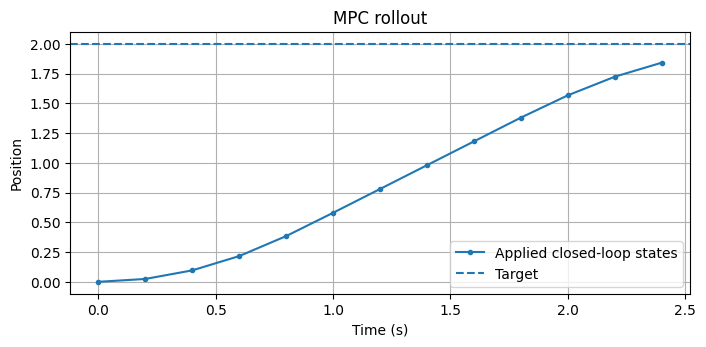

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(dt * np.arange(steps + 1), states[:, 0], marker=".", label="Applied closed-loop states")
ax.axhline(target[0], linestyle="--", label="Target")
ax.set(xlabel="Time (s)", ylabel="Position", title="MPC rollout")
ax.grid(True)
ax.legend()
plt.show()

## Using measurements and changing models
Replace the simulation line with your measured state. Use `solver.update(problem)` whenever
coefficients change; do not mutate private workspace buffers or assume unchanged shapes imply
unchanged numeric factors. Change `q` and `f` when changing the target.

`CHECK_FRESH_WORKSPACE` is an extra teaching check. Turn it off for a real-time loop.
Reporting, plotting, and diagnostic replay should stay outside your latency-critical section.